# 10장 LLM 기반 질의 선택

루프의 3단계(질의 전략)에 Jev를 넣는다. 학생 모델의 엔트로피로 풀을 후보 M개로 줄이고, Jev가 후보마다 판정한 결과로 만든 점수로 k개를 고른다. Jev는 텍스트를 생성하지 않고 판정 질문(choice·noul·score)에 확률로 답하는 API다. 그래서 「Jev가 고른다」가 아니라 「Jev가 판정하고 그 판정으로 고른다」는 형태가 된다.

- 10.1 Jev 질의 선택기의 구조
- 10.2 후보 축소 — 불확실성 상위 M
- 10.3 재순위화 프롬프트 설계
- 10.4 구조화 출력과 응답 파싱
- 10.5 질의 함수 시그니처 호환 구현
- 10.6 전통 전략과의 학습 곡선 비교
- 10.7 후보 크기와 호출 비용

학생 모델은 1부와 같은 TF-IDF·로지스틱 회귀이고 CPU로 돈다. 예산도 1부와 같은 라벨 2,000개다. 라벨은 시뮬레이션 사람 오라클(정답)이 붙인다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피 점수와 8장의 클러스터 질의를 기준선으로 다시 싣는다. 클러스터는 8장에서 엔트로피와 대등했던 유일한 다양성 전략이다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

In [3]:
# ── 다양성 임베딩과 클러스터 질의(8장) ────
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

for d in DATA.values():
    Z = TruncatedSVD(256, random_state=42).fit(d["X_pool"]).transform(d["X_pool"]).astype(np.float32)
    d["Z"] = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def query_cluster(model, data, idx_l, y_l, idx_u, k, rng, m=10):
    h = score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
    top = np.argsort(-h)[:m * k]
    lab = KMeans(k, n_init=1, random_state=int(rng.integers(2**31))).fit_predict(data["Z"][idx_u[top]])
    pick = [top[lab == c][np.argmax(h[top[lab == c]])] for c in range(k)]
    return idx_u[np.array(pick)]

## 10.1 Jev 질의 선택기의 구조

Jev 질의 선택기는 2장의 `query_fn` 시그니처를 그대로 따른다. 안에서 하는 일은 넷이다. 남은 풀을 엔트로피로 후보 M개까지 줄이고, 후보를 50개씩 묶어 판정 질문을 만들고, Jev를 부르고, 판정을 점수로 바꿔 상위 k개를 고른다. 루프 본문과 오라클은 손대지 않는다.

Jev 호출은 `jev_ask` 하나로 한다. 요청은 판단할 내용(`state`)과 이름 붙인 질문 묶음(`questions`)이고, 응답은 질문 이름별 답과 입력·출력 토큰 수다. 키·주소·모델 이름이 출력에 찍히지 않도록 환경변수는 설정 여부만 출력하고 오류 메시지도 가린다.

In [4]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64):                       # 일시 오류(429·5xx)는 잠시 쉬고 다시 보낸다
        r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                         json=body, timeout=300)
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [5]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

## 10.2 후보 축소 — 불확실성 상위 M

풀은 2만 개에 가깝다. 매 라운드 풀 전체를 판정하면 라운드마다 입력 토큰이 수십만 개에 이른다. 그래서 엔트로피 상위 M개만 후보로 남긴다. 기본값은 M = 3k = 150이다. Jev는 엔트로피가 이미 높다고 본 150개 안에서 순위를 다시 매기는 셈이다.

후보는 섞은 순서로 묶는다. 엔트로피 순서대로 늘어놓으면 목록의 위치가 점수를 흘린다.

In [6]:
# ── 후보 축소 ────
M_DEFAULT, CHUNK = 150, 50

def shortlist(model, data, pool, M, rng):
    # pool 가운데 엔트로피 상위 M개를 고르고 섞은 순서로 돌려준다
    P = proba(model, data["X_pool"][pool], data["n_classes"])
    h = score_entropy(P)
    top = np.argsort(-h)[:M]
    perm = rng.permutation(len(top))
    return pool[top][perm], P[top][perm], h[top][perm]

## 10.3 재순위화 프롬프트 설계

후보 50개를 번호를 붙여 `state` 하나에 넣고 후보마다 질문 두 개를 붙인다.

- `label_i` (choice): i번 문장의 라벨. 선택지는 라벨 이름과 설명이다.
- `info_i` (score): i번 문장에 라벨을 붙이면 분류기가 얼마나 새로 배울까. 0 「거의 없다」부터 3 「매우 많다」까지 네 단계다. 질문에 학생 분류기의 예측과 신뢰도를 적는다. 블라인드 판정은 이 부분을 뺀다.

Jev의 답은 확률이다. choice는 선택지별 확률을, score는 단계별 확률과 그 기댓값(기대 점수)을 돌려준다.

In [7]:
# ── 판정 질문 ────
INFO_LEVELS = ["거의 없다 — 분류기가 이미 맞게 아는 내용이거나 뜻이 없는 문장",
               "조금 — 비슷한 문장을 이미 많이 봤을 것이다",
               "많다 — 분류기가 헷갈리거나 틀릴 만한 문장",
               "매우 많다 — 라벨을 알면 분류 경계가 크게 바뀔 문장"]

def build_questions(data, texts, P, blind=False):
    names = LABEL_NAMES[data["name"]]
    state = "\n".join(f"[{i}] " + str(t).replace("\n", " ") for i, t in enumerate(texts))
    qs = {}
    for i, p in enumerate(P):
        qs[f"label_{i}"] = {"type": "choice", "instructions": f"[{i}]번 문장의 {TASK[data['name']]}은?",
                            "criteria": LABEL_DESC[data["name"]]}
        seen = "" if blind else f" 지금 분류기의 예측은 {names[p.argmax()]}, 확률 {p.max():.2f}이다."
        qs[f"info_{i}"] = {"type": "score", "criteria": INFO_LEVELS,
                           "instructions": f"{TASK[data['name']]} 분류기를 학습시킬 때 [{i}]번 문장에 라벨을 붙이면 분류기가 얼마나 새로 배울까?{seen}"}
    return state, qs

state0, qs0 = build_questions(DATA["nsmc"], DATA["nsmc"]["texts"][:3], np.array([[0.4, 0.6], [0.9, 0.1], [0.5, 0.5]]))
print(state0)
print(qs0["label_0"])
print(qs0["info_0"])

import json

# 후보 50개 요청 하나에서 문장(state)과 질문 정의(questions)의 글자 수
for name, d in DATA.items():
    st, qs = build_questions(d, d["texts"][:50], np.full((50, d["n_classes"]), 1 / d["n_classes"]))
    n_q = len(json.dumps(qs, ensure_ascii=False))
    print(f"{name}: state {len(st):,}자 | questions {n_q:,}자 | 질문 비중 {n_q / (len(st) + n_q):.0%}")

[0] 1편보단 재밌지만 별로다
[1] 영환가?
[2] 아니 이렇게 재미없는걸 왜 재밌다고 하세요? 정말..
{'type': 'choice', 'instructions': '[0]번 문장의 영화 리뷰의 감성은?', 'criteria': {'부정': '영화를 부정적으로 평가한 리뷰', '긍정': '영화를 긍정적으로 평가한 리뷰'}}
{'type': 'score', 'criteria': ['거의 없다 — 분류기가 이미 맞게 아는 내용이거나 뜻이 없는 문장', '조금 — 비슷한 문장을 이미 많이 봤을 것이다', '많다 — 분류기가 헷갈리거나 틀릴 만한 문장', '매우 많다 — 라벨을 알면 분류 경계가 크게 바뀔 문장'], 'instructions': '영화 리뷰의 감성 분류기를 학습시킬 때 [0]번 문장에 라벨을 붙이면 분류기가 얼마나 새로 배울까? 지금 분류기의 예측은 긍정, 확률 0.60이다.'}
nsmc: state 2,027자 | questions 20,810자 | 질문 비중 91%
ynat: state 1,731자 | questions 25,910자 | 질문 비중 94%


## 10.4 구조화 출력과 응답 파싱

`judge` 가 후보를 50개씩 묶어 Jev를 부르고 답을 배열로 정리한다. Jev 라벨 확률은 라벨 순서대로 늘어놓은 행렬 `PJ` 로, 정보성은 기대 점수 벡터 `info` 로 만든다. 확률 사전에 빠진 선택지는 0으로 둔다.

먼저 시드 0의 첫 라운드 후보 150개로 한 번 판정해 본다. Jev 라벨의 정답률, 정보성 점수의 분포, 토큰 수, 같은 요청을 다시 보냈을 때의 차이를 확인한다.

In [8]:
# ── 판정 함수 ────
def judge(data, cand, P, blind=False):
    names = LABEL_NAMES[data["name"]]
    PJ, info, n_in, n_out, calls = [], [], 0, 0, 0
    for s in range(0, len(cand), CHUNK):
        state, qs = build_questions(data, data["texts"][cand[s:s + CHUNK]], P[s:s + CHUNK], blind)
        ans, a, b = jev_ask(state, qs)
        n_in, n_out, calls = n_in + a, n_out + b, calls + 1
        for i in range(len(cand[s:s + CHUNK])):
            PJ.append([ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names])
            info.append(ans[f"info_{i}"]["score"])
    PJ = np.array(PJ)
    return PJ / PJ.sum(1, keepdims=True), np.array(info), dict(n_in=n_in, n_out=n_out, calls=calls)

In [9]:
# ── 첫 호출 점검 ────
d = DATA["nsmc"]
rng0 = np.random.default_rng(0)
idx_l0 = rng0.choice(len(d["y_pool"]), N_INIT, replace=False)
m0 = train_model(d["X_pool"][idx_l0], d["y_pool"][idx_l0], 0)
cand0, P0, h0 = shortlist(m0, d, np.setdiff1d(np.arange(len(d["y_pool"])), idx_l0), M_DEFAULT, rng0)

t0 = time.perf_counter()
PJ0, info0, st0 = judge(d, cand0, P0)
print(f"판정 {time.perf_counter() - t0:.1f}초 | {st0}")
y0 = d["y_pool"][cand0]
print("후보 150개에서 Jev 라벨 정답률:", round((PJ0.argmax(1) == y0).mean(), 4),
      "| 학생 모델 정답률:", round((P0.argmax(1) == y0).mean(), 4))
print("정보성 기대 점수 분포:", np.percentile(info0, [0, 25, 50, 75, 100]).round(2))
print("정보성과 엔트로피의 순위 상관:", round(pd.Series(info0).corr(pd.Series(h0), method="spearman"), 4))
PJ1, info1, _ = judge(d, cand0, P0)
print("같은 요청 재전송 — 라벨 확률 최대 차이:", round(np.abs(PJ0 - PJ1).max(), 4), "| 정보성 최대 차이:", round(np.abs(info0 - info1).max(), 4))

판정 0.9초 | {'n_in': 44273, 'n_out': 7699, 'calls': 3}
후보 150개에서 Jev 라벨 정답률: 0.9133 | 학생 모델 정답률: 0.44
정보성 기대 점수 분포: [0.6  1.08 1.38 1.58 1.98]
정보성과 엔트로피의 순위 상관: 0.0367


같은 요청 재전송 — 라벨 확률 최대 차이: 0.09 | 정보성 최대 차이: 0.16


## 10.5 질의 함수 시그니처 호환 구현

`make_jev_query(mode, M)` 이 2장 시그니처의 질의 함수를 만든다. 질의 함수는 라운드마다 호출 기록(`stats`)과 고른 샘플의 판정(`picks`)을 자기 속성에 쌓는다. 모드는 넷이다.

| 모드 | 후보 | 점수 |
|---|---|---|
| `kl` | 엔트로피 상위 M | Jev 불일치 KL(p_Jev ‖ p_θ) |
| `info` | 엔트로피 상위 M | 정보성 기대 점수(학생 예측 제시) |
| `info_blind` | 엔트로피 상위 M | 정보성 기대 점수(학생 예측 숨김) |
| `info_rand` | 남은 풀에서 무작위 M | 정보성 기대 점수(학생 예측 제시) |

점수가 같으면 엔트로피가 큰 쪽을 앞세운다. 라운드마다 고른 k개가 같은 라운드 엔트로피 상위 k개와 몇 개 겹치는지도 기록한다. 겹침이 k에 가까우면 Jev 판정이 엔트로피 순서를 거의 바꾸지 않은 것이다.

In [10]:
# ── Jev 질의 함수 ────
def kl_div(PJ, P):
    return (PJ * (np.log(PJ + 1e-12) - np.log(P + 1e-12))).sum(1)

def make_jev_query(mode, M=M_DEFAULT):
    stats, picks = [], []
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        Pu = proba(model, data["X_pool"][idx_u], data["n_classes"])
        top_h = set(idx_u[np.argsort(-score_entropy(Pu))[:k]])
        pool = rng.choice(idx_u, M, replace=False) if mode == "info_rand" else idx_u
        cand, P, h = shortlist(model, data, pool, M, rng)
        t0 = time.perf_counter()
        PJ, info, st = judge(data, cand, P, blind=(mode == "info_blind"))
        s = kl_div(PJ, P) if mode == "kl" else info
        sel = np.lexsort((-h, -s))[:k]                         # 점수 내림차순, 같으면 엔트로피 내림차순
        y = data["y_pool"][cand]
        stats.append(dict(**st, t_jev=time.perf_counter() - t0, jev_acc=(PJ.argmax(1) == y).mean(),
                          overlap=len(top_h & set(cand[sel]))))
        picks.extend(dict(round=len(stats) - 1, idx=int(cand[i]), score=float(s[i]), info=float(info[i]),
                          jev_label=int(PJ[i].argmax()), jev_conf=float(PJ[i].max()), entropy=float(h[i])) for i in sel)
        return cand[sel]
    query_fn.stats, query_fn.picks = stats, picks
    return query_fn

## 10.6 전통 전략과의 학습 곡선 비교

기준선 셋(Random, 엔트로피, 클러스터)은 4장 방식대로 CPU 코어에 나눠 돌린다. 1부와 같은 환경이므로 Random과 엔트로피는 3장 결과 파일과 같은 값이 나와야 한다.

Jev 전략은 시드 5개를 스레드로 동시에 돌린다. (데이터, 전략, 시드)마다 결과를 `results/ch10_parts/` 에 저장해 실행이 끊겨도 이어서 돌 수 있게 한다.

In [11]:
# ── 기준선 실험 ────
BASE = {"Random": query_random, "엔트로피": query_entropy, "클러스터": query_cluster}
base = {}
for name, d in DATA.items():
    base[name] = run_strategies(BASE, d)
    ch03 = pd.read_csv(f"results/ch03_{name}.csv")
    for s in ("Random", "엔트로피"):
        diff = np.abs(ch03[ch03.strategy == s].f1.values - base[name][base[name].strategy == s].f1.values).max()
        print(name, s, "3장 대비 F1 최대 차이:", diff)

nsmc  Random, 엔트로피, 클러스터 완료
nsmc Random 3장 대비 F1 최대 차이: 5.551115123125783e-17
nsmc 엔트로피 3장 대비 F1 최대 차이: 5.551115123125783e-17


ynat  Random, 엔트로피, 클러스터 완료
ynat Random 3장 대비 F1 최대 차이: 8.326672684688674e-17
ynat 엔트로피 3장 대비 F1 최대 차이: 8.326672684688674e-17


In [12]:
# ── Jev 전략 실험 ────
os.makedirs("results/ch10_parts", exist_ok=True)

def run_jev(name, mode, M, d, seed):
    path = f"results/ch10_parts/{d['name']}_{mode}{M}_{seed}.csv"
    if os.path.exists(path):
        return pd.read_csv(path)
    q = make_jev_query(mode, M)
    t0 = time.perf_counter()
    df, _ = run_loop(q, make_sim_oracle(d["y_pool"]), d, seed)
    df = pd.concat([df, pd.DataFrame(q.stats)], axis=1).assign(strategy=name, wall=time.perf_counter() - t0)
    df.to_csv(path, index=False)
    pd.DataFrame(q.picks).assign(seed=seed).to_csv(path.replace(".csv", "_picks.csv"), index=False)
    return df

def run_jev_all(name, mode, M, d):
    with ThreadPoolExecutor(MAX_CONC) as ex:
        return pd.concat(list(ex.map(lambda s: run_jev(name, mode, M, d, s), SEEDS)), ignore_index=True)

JEV_STRATS = {"Jev 불일치": "kl", "Jev 정보성": "info", "Jev 정보성·블라인드": "info_blind",
              "Jev 정보성·무작위 후보": "info_rand"}
jev = {}
for name, d in DATA.items():
    t0 = time.perf_counter()
    jev[name] = pd.concat([run_jev_all(s, m, M_DEFAULT, d) for s, m in JEV_STRATS.items()], ignore_index=True)
    print(f"{name} Jev 전략 완료 {(time.perf_counter() - t0) / 60:.1f}분")

nsmc Jev 전략 완료 0.0분


ynat Jev 전략 완료 0.0분



nsmc 매크로 F1 (라벨 100~2,000)
                   ALC  ALC_std   final      LE  t_query  ALC_min  ALC_max
strategy                                                                  
Random          0.7426   0.0034  0.7802  1.0000   0.0001   0.7359   0.7448
엔트로피            0.7479   0.0055  0.7860  1.2121   0.0429   0.7387   0.7529
클러스터            0.7464   0.0019  0.7854  1.1429   0.2250   0.7443   0.7490
Jev 불일치         0.7694   0.0034  0.8057  2.2222   0.9560   0.7634   0.7735
Jev 정보성         0.7031   0.0143  0.7550     NaN   0.8821   0.6792   0.7147
Jev 정보성·블라인드    0.6984   0.0044  0.7478     NaN   0.8496   0.6912   0.7042
Jev 정보성·무작위 후보  0.7262   0.0052  0.7628     NaN   0.8300   0.7215   0.7357
nsmc Jev 호출 (라운드 평균, n_in_run은 실행 하나의 입력 토큰 합)
                     n_in     n_out  calls  t_jev  jev_acc  overlap   n_in_run
strategy                                                                      
Jev 불일치         44067.942  7675.595    3.0  0.886    0.821   17.279  1674581.8
Jev 정보성      

                   ALC  ALC_std   final      LE  t_query  ALC_min  ALC_max
strategy                                                                  
Random          0.5335   0.0068  0.6500  1.0000   0.0005   0.5222   0.5402
엔트로피            0.6164   0.0048  0.7202  2.0000   0.2367   0.6098   0.6236
클러스터            0.6219   0.0084  0.7207  2.0000   0.3140   0.6123   0.6352
Jev 불일치         0.6078   0.0042  0.7208  1.8182   1.2063   0.6023   0.6130
Jev 정보성         0.6189   0.0061  0.7152  1.9048   1.0738   0.6124   0.6287
Jev 정보성·블라인드    0.6124   0.0127  0.7187  1.9048   1.0850   0.5877   0.6242
Jev 정보성·무작위 후보  0.6152   0.0094  0.7007  1.6667   1.0052   0.5984   0.6236
ynat Jev 호출 (라운드 평균, n_in_run은 실행 하나의 입력 토큰 합)


                     n_in      n_out  calls  t_jev  jev_acc  overlap   n_in_run
strategy                                                                       
Jev 불일치         56726.479  13621.832    3.0  0.994    0.583   10.516  2155606.2
Jev 정보성         56718.747  13639.621    3.0  0.932    0.756   11.905  2155312.4
Jev 정보성·블라인드    53807.147  13687.153    3.0  0.952    0.823    9.147  2044671.6
Jev 정보성·무작위 후보  56780.126  13634.826    3.0  0.938    0.791    0.326  2157644.8


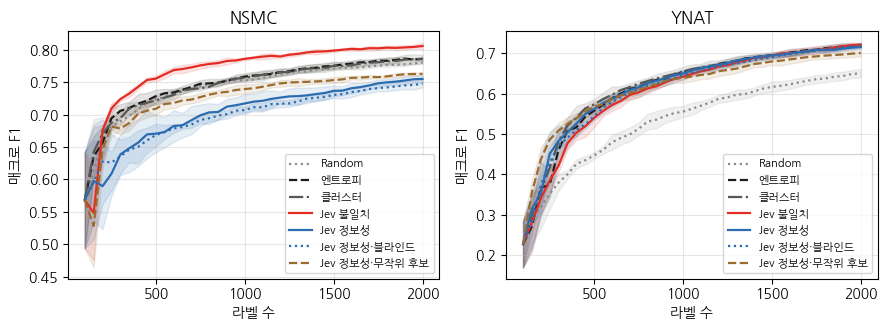

In [13]:
# ── 학습 곡선과 지표 ────
STYLES = [(GRAY2, ":"), (INK, "--"), (GRAY, "-."), (ACCENT, "-"), ("#2B6CB0", "-"), ("#2B6CB0", ":"), ("#9C6B30", "--")]
res = {name: pd.concat([base[name], jev[name]], ignore_index=True) for name in DATA}

def alc_range(r, metric="f1"):
    a = r.groupby(["strategy", "seed"], sort=False).apply(lambda g: alc(g.n_labeled.values, g[metric].values), include_groups=False)
    return a.groupby(level=0, sort=False).agg(ALC_min="min", ALC_max="max").round(4)

def jev_usage(r):
    g = r[r.n_in.notna()]
    return g.groupby("strategy", sort=False).agg(n_in=("n_in", "mean"), n_out=("n_out", "mean"), calls=("calls", "mean"),
                                                  t_jev=("t_jev", "mean"), jev_acc=("jev_acc", "mean"),
                                                  overlap=("overlap", "mean"),
                                                  n_in_run=("n_in", lambda x: x.sum() / len(SEEDS))).round(3)

for name, r in res.items():
    print(f"\n{name} 매크로 F1 (라벨 100~2,000)")
    print(summarize(r, "f1").set_index("strategy").join(alc_range(r)).to_string())
    print(f"{name} Jev 호출 (라운드 평균, n_in_run은 실행 하나의 입력 토큰 합)")
    print(jev_usage(r).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r, "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch10_curves.png", dpi=200)

Jev 정보성이 높게 매긴 샘플과 낮게 매긴 샘플을 본다. 시드 0의 Jev 정보성 전략에서 라운드 0과 20의 선택 가운데 정보성 점수가 가장 높은 셋을 정답 라벨, Jev 라벨과 함께 출력한다. 같은 라운드 후보 가운데 점수가 낮아 버려진 샘플은 기록하지 않으므로 고른 샘플만 본다.

In [14]:
# ── 선택 예시 ────
for name, d in DATA.items():
    pk = pd.read_csv(f"results/ch10_parts/{name}_info{M_DEFAULT}_0_picks.csv")
    names = LABEL_NAMES[name]
    print(f"\n{name}")
    for r in (0, 20):
        for _, p in pk[pk["round"] == r].nlargest(3, "info").iterrows():
            print(f"  라운드 {r:2d} | 정보성 {p['info']:.2f} | 정답={names[d['y_pool'][int(p.idx)]]} Jev={names[int(p.jev_label)]}({p.jev_conf:.2f}) | {str(d['texts'][int(p.idx)])[:40]}")


nsmc
  라운드  0 | 정보성 2.05 | 정답=긍정 Jev=긍정(0.99) | 이영화는인생을 말하는것입니다. 여기서 사라지는 것은 나이를 먹든 병에 걸
  라운드  0 | 정보성 1.93 | 정답=긍정 Jev=긍정(0.98) | 신부님 처럼 일하는 사람이 몇이나 있겠는가..정말 보고 배울점이 많다..
  라운드  0 | 정보성 1.91 | 정답=부정 Jev=부정(0.80) | 나 들어가야돼 들어가고 싶어!!! 아 보면서 답답해 죽는 줄 알았다
  라운드 20 | 정보성 2.00 | 정답=긍정 Jev=긍정(0.60) | 정체된 집단에서 그들만의 언어로 사고하고 의사소통 하는 것이 얼마나 위험
  라운드 20 | 정보성 1.91 | 정답=부정 Jev=부정(0.95) | 어릴땐 완전 감동 그러나 알고보니 유유백서 표절
  라운드 20 | 정보성 1.91 | 정답=부정 Jev=부정(1.00) | 물론군인분들의희생은너무나도슬펐습니다하지만이런영화는나와선안됩니다김대중대통령

ynat
  라운드  0 | 정보성 2.37 | 정답=IT과학 Jev=IT과학(0.99) | 우주질량 80% 차지한 암흑물질 정체 밝혀지나
  라운드  0 | 정보성 2.29 | 정답=스포츠 Jev=스포츠(1.00) | 강민호 삼성 이적 첫 안타가 홈런…KIA전 솔로포
  라운드  0 | 정보성 2.25 | 정답=생활문화 Jev=생활문화(0.82) | 백남준 알렉산더 대왕 홍콩 경매 출품
  라운드 20 | 정보성 2.28 | 정답=생활문화 Jev=생활문화(0.90) | 한국 페미니즘 미술 다시 보기
  라운드 20 | 정보성 2.28 | 정답=사회 Jev=정치(0.64) | 30년 맞은 87년 체제의 미래는…학계서 집중 조명
  라운드 20 | 정보성 2.21 | 정답=정치 Jev=정치(0.96) | 황교안 저부터 먼저 짓밟히겠다…끝까지 고발당한 분 지킨다종합


## 10.7 후보 크기와 호출 비용

10.6절에서 두 데이터의 평균 ALC가 더 높았던 Jev 전략(불일치 또는 정보성)의 후보 수 M을 2k(100), 3k(150), 6k(300), 20k(1,000)로 바꾼다. M = 1,000은 라운드당 입력 토큰이 M = 150의 7배 가까이 들어 NSMC에서만 돌리고, YNAT는 300까지 돌린다. M이 클수록 Jev 판단의 비중이 커지고 엔트로피의 비중은 작아진다. M = k(50)이면 엔트로피와 같다.

두 데이터 평균 ALC: {'Jev 불일치': 0.6886, 'Jev 정보성': 0.661} → 후보 크기 실험: Jev 불일치

nsmc 후보 크기별 (라벨 효율 기준: 엔트로피의 라벨 2,000 성능)
                   ALC  ALC_std   final      LE  t_query        n_in      n_out  calls  t_jev  jev_acc  overlap    n_in_run  ALC_min  ALC_max
strategy                                                                                                                                     
엔트로피            0.7479   0.0055  0.7860  1.0526   0.0429         NaN        NaN    NaN    NaN      NaN      NaN         NaN   0.7387   0.7529
Jev 불일치 M=100   0.7640   0.0021  0.8010  1.5385   0.6660   29344.026   5117.574    2.0  0.590    0.822   25.047   1115073.0   0.7618   0.7673
Jev 불일치 M=150   0.7694   0.0034  0.8057  1.9048   0.9560   44067.942   7675.595    3.0  0.886    0.821   17.279   1674581.8   0.7634   0.7735
Jev 불일치 M=300   0.7721   0.0014  0.8077  1.9048   1.7438   88142.737  15350.689    6.0  1.686    0.808    8.911   3349424.0   0.7706   0.7743
Jev 불일치 M=1000  0.7733   0.0031  

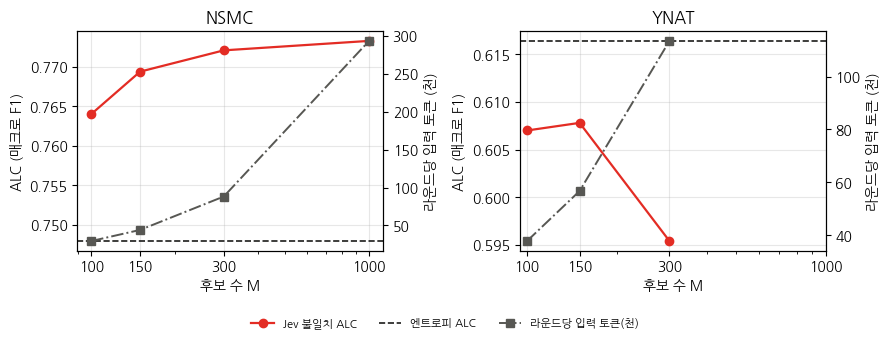

In [15]:
# ── 후보 크기 실험 ────
mean_alc = {s: np.mean([summarize(res[n], "f1").set_index("strategy").loc[s, "ALC"] for n in DATA]) for s in ("Jev 불일치", "Jev 정보성")}
best = max(mean_alc, key=mean_alc.get)
print("두 데이터 평균 ALC:", {s: round(v, 4) for s, v in mean_alc.items()}, "→ 후보 크기 실험:", best)

SIZES = {"nsmc": (100, 150, 300, 1000), "ynat": (100, 150, 300)}
size = {}
for name, d in DATA.items():
    extra = [run_jev_all(f"{best} M={M}", JEV_STRATS[best], M, d) for M in SIZES[name] if M != 150]
    size[name] = pd.concat([res[name][res[name].strategy.isin(["엔트로피", best])].replace({"strategy": {best: f"{best} M=150"}}),
                            *extra], ignore_index=True)

tabs = {}
for name, r in size.items():
    t = summarize(r, "f1", ref="엔트로피").set_index("strategy").join(jev_usage(r)).join(alc_range(r))
    order = ["엔트로피"] + [f"{best} M={M}" for M in SIZES[name]]
    tabs[name] = t.loc[order]
    print(f"\n{name} 후보 크기별 (라벨 효율 기준: 엔트로피의 라벨 2,000 성능)")
    print(tabs[name].to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, t) in zip(axes, tabs.items()):
    Ms = list(SIZES[name])
    ax.plot(Ms, t.ALC.values[1:], color=ACCENT, marker="o", lw=1.6, label=f"{best} ALC")
    ax.axhline(t.ALC.values[0], color=INK, ls="--", lw=1.2, label="엔트로피 ALC")
    ax2 = ax.twinx()
    ax2.plot(Ms, t.n_in.values[1:] / 1000, color=GRAY, marker="s", ls="-.", lw=1.4, label="라운드당 입력 토큰(천)")
    ax.set(title=name.upper(), xlabel="후보 수 M", ylabel="ALC (매크로 F1)", xscale="log", xticks=SIZES["nsmc"], xticklabels=SIZES["nsmc"])
    ax2.set_ylabel("라운드당 입력 토큰 (천)")
    ax.grid(alpha=0.3)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig("out/ch10_cand_size.png", dpi=200)

마지막으로 라벨 하나를 아끼는 데 든 Jev 입력 토큰을 계산한다. 엔트로피가 라벨 2,000개로 낸 평균 매크로 F1에 Jev 전략이 처음 닿은 라벨 수를 n*라 하면 아낀 라벨은 2,000 − n*개다. n*에 닿을 때까지 쓴 입력 토큰(시드 평균)을 아낀 라벨 수로 나눈다. 엔트로피 성능에 닿지 못한 전략은 비워 둔다.

In [16]:
# ── 라벨 하나를 아끼는 데 든 토큰 ────
rows = []
for name in DATA:
    r = pd.concat([res[name], size[name][size[name].strategy.str.contains("M=") & ~size[name].strategy.str.endswith("M=150")]], ignore_index=True)
    target = r[r.strategy == "엔트로피"].groupby("n_labeled").f1.mean().loc[BUDGET]
    for s, g in r[r.strategy.str.startswith("Jev")].groupby("strategy", sort=False):
        curve = g.groupby("n_labeled").f1.mean()
        hit = curve.index[curve.values >= target]
        n_star = hit[0] if len(hit) else np.nan
        spent = g[g.n_labeled < n_star].n_in.sum() / len(SEEDS)
        rows.append(dict(data=name, strategy=s, n_star=n_star, saved=BUDGET - n_star,
                         tokens_to_n_star=round(spent) if len(hit) else np.nan,
                         tokens_per_saved_label=round(spent / (BUDGET - n_star)) if len(hit) and n_star < BUDGET else np.nan))
print(pd.DataFrame(rows).to_string(index=False))

data       strategy  n_star  saved  tokens_to_n_star  tokens_per_saved_label
nsmc        Jev 불일치  1050.0  950.0          838052.0                   882.0
nsmc        Jev 정보성     NaN    NaN               NaN                     NaN
nsmc   Jev 정보성·블라인드     NaN    NaN               NaN                     NaN
nsmc Jev 정보성·무작위 후보     NaN    NaN               NaN                     NaN
nsmc  Jev 불일치 M=100  1300.0  700.0          705081.0                  1007.0
nsmc  Jev 불일치 M=300  1050.0  950.0         1677618.0                  1766.0
nsmc Jev 불일치 M=1000   950.0 1050.0         5001119.0                  4763.0
ynat        Jev 불일치  2000.0    0.0         2155606.0                     NaN
ynat        Jev 정보성     NaN    NaN               NaN                     NaN
ynat   Jev 정보성·블라인드     NaN    NaN               NaN                     NaN
ynat Jev 정보성·무작위 후보     NaN    NaN               NaN                     NaN
ynat  Jev 불일치 M=100     NaN    NaN               NaN                     NaN

In [17]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = [f for f in glob.glob("results/ch10_parts/*.csv") if not f.endswith(("_picks.csv", "_log.csv"))]
total = sum(pd.read_csv(f).filter(regex="^n_in").sum().sum() for f in files)
print(f"결과 파일에 기록된 Jev 입력 토큰 합: {total:,.0f}")

결과 파일에 기록된 Jev 입력 토큰 합: 182,309,391
